# FraudShield - Final Reproducible Experiment

**Research question:** How effectively can supervised machine-learning models identify fraudulent credit card transactions while balancing fraud detection and false-positive rates on unseen data?

This notebook compares a majority-class baseline, class-weighted logistic regression, and XGBoost under the same evaluation conditions. The original project considered graph-based features, but the dataset does not include persistent account, cardholder, or merchant identifiers. A graph would therefore require constructed similarity relationships rather than observed financial connections, so the final experiment focuses on a valid tabular comparison.


In [1]:
import os
import sys
import platform
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, precision_recall_curve
)
from xgboost import XGBClassifier

# One seed is reused everywhere (randomness is involved).
SEED = 42
THRESHOLD = 0.50
np.random.seed(SEED)

# Look for the dataset in common locations (local/Colab).
candidate_paths = [
    'creditcard.csv',
    '/content/creditcard.csv',
    '/mnt/data/fraudshield_cp2/creditcard.csv',
]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError('creditcard.csv was not found. Ensure it is in this notebook or upload it to Colab.')

print('Dataset:', DATA_PATH)
print('Seed:', SEED)
print('Classification threshold:', THRESHOLD)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('XGBoost:', xgboost.__version__)
print('Platform:', platform.platform())
print('CPU cores available:', os.cpu_count())


Dataset: creditcard.csv
Seed: 42
Classification threshold: 0.5
Python: 3.13.16
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
XGBoost: 3.4.1
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
CPU cores available: 2


## 1. Load and clean the data

The ULB credit card fraud dataset contains anonymized transaction features `V1` through `V28`, plus `Time`, `Amount`, and the target `Class`. I remove exact duplicate rows and verify that there are no missing values.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print('Raw shape:', df_raw.shape)
print('Missing values:', int(df_raw.isna().sum().sum()))
print('Duplicate rows:', int(df_raw.duplicated().sum()))
print(df_raw['Class'].value_counts())

df = df_raw.drop_duplicates().reset_index(drop=True)
df = df.dropna()
print()
print('Clean shape:', df.shape)
print('Fraud cases after cleaning:', int(df['Class'].sum()))

Raw shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081
Class
0    284315
1       492
Name: count, dtype: int64

Clean shape: (283726, 31)
Fraud cases after cleaning: 473


## 2. Create one shared 60/20/20 split

All models use the same stratified 60% training, 20% validation, and 20% test split. The validation set is used to check model behavior during development. The test set is reserved for the final reported evaluation. The seed is fixed at `42`, and the classification threshold remains fixed at `0.50`.


In [3]:
X = df.drop(columns='Class')
y = df['Class'].astype(int)

# Hold out 20% test set.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Then take 25% of the remaining 80% (which is 20% of the full dataset).
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=SEED,
    stratify=y_train_val
)

print('Training cases:', len(y_train), '| Fraud:', int(y_train.sum()))
print('Validation cases:', len(y_val), '| Fraud:', int(y_val.sum()))
print('Test cases:', len(y_test), '| Fraud:', int(y_test.sum()))
print('Total cases:', len(y_train) + len(y_val) + len(y_test))


Training cases: 170235 | Fraud: 284
Validation cases: 56745 | Fraud: 94
Test cases: 56746 | Fraud: 95
Total cases: 283726


## 3. Train the baseline and ML models

- Majority baseline: predicts every transaction as legitimate.
- Balanced logistic regression: simple linear classifier with class balancing.
- XGBoost: nonlinear tree-based classifier with class weighting for the severe fraud imbalance.

All models are trained only on the 60% training set. Logistic regression standardizes only `Time` and `Amount` inside a pipeline, so the scaler is fit on training data only. XGBoost uses the cleaned tabular features directly. XGBoost uses one CPU thread to reduce run-to-run variation.


In [4]:
scale_columns = ['Time', 'Amount']
other_columns = [c for c in X.columns if c not in scale_columns]

preprocess = ColumnTransformer([
    ('scale', StandardScaler(), scale_columns),
    ('keep', 'passthrough', other_columns)
])

# Class weighting is calculated from the training set only.
negative_count, positive_count = np.bincount(y_train)
scale_pos_weight = negative_count / positive_count

models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Balanced logistic regression': Pipeline([
        ('preprocess', preprocess),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=SEED
        ))
    ]),
    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective='binary:logistic',
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        n_jobs=1,
        tree_method='hist'
    )
}

def evaluate_model(name, model, X_eval, y_eval, split_name):
    prob = model.predict_proba(X_eval)[:, 1]
    pred = (prob >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred, labels=[0, 1]).ravel()

    row = {
        'Model': name,
        'Split': split_name,
        'Cases': len(y_eval),
        'Fraud cases': int(y_eval.sum()),
        'Precision': precision_score(y_eval, pred, zero_division=0),
        'Recall': recall_score(y_eval, pred, zero_division=0),
        'F1': f1_score(y_eval, pred, zero_division=0),
        'PR-AUC': average_precision_score(y_eval, prob),
        'ROC-AUC': roc_auc_score(y_eval, prob),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)
    }
    return row, pred, prob

# Fit once on the training set (more reproducibility).
for model in models.values():
    model.fit(X_train, y_train)

# Validation results are checked before the final test results.
validation_rows = []
for name, model in models.items():
    row, _, _ = evaluate_model(name, model, X_val, y_val, 'Validation')
    validation_rows.append(row)

validation_df = pd.DataFrame(validation_rows)
validation_df[['Model','Cases','Fraud cases','Precision','Recall','F1','PR-AUC','TP','FP','FN']]


,Model,Cases,Fraud cases,Precision,Recall,F1,PR-AUC,TP,FP,FN
0,Majority baseline,56745,94,0.000000,0.000000,0.000000,0.001657,0,0,94
1,Balanced logistic regression,56745,94,0.053832,0.904255,0.101614,0.786826,85,1494,9
2,XGBoost,56745,94,0.719298,0.872340,0.788462,0.876905,82,32,12


## 4. Final evaluation on the untouched test set

The following table contains the final reported results. PR-AUC is the main ranking metric because fraud is extremely rare. Precision, recall, F1, and false positives show the practical tradeoff between catching fraud and generating false alarms. No threshold tuning is performed on the test set.


In [5]:
test_rows = []
predictions = {}
probabilities = {}

for name, model in models.items():
    row, pred, prob = evaluate_model(name, model, X_test, y_test, 'Test')
    test_rows.append(row)
    predictions[name] = pred
    probabilities[name] = prob

results_df = pd.DataFrame(test_rows)
display_table = results_df.copy()
for c in ['Precision', 'Recall', 'F1', 'PR-AUC', 'ROC-AUC']:
    display_table[c] = display_table[c].round(3)

display_table[['Model','Cases','Fraud cases','Precision','Recall','F1','PR-AUC','TP','FP','FN']]


,Model,Cases,Fraud cases,Precision,Recall,F1,PR-AUC,TP,FP,FN
0,Majority baseline,56746,95,0.000,0.000,0.000,0.002,0,0,95
1,Balanced logistic regression,56746,95,0.051,0.874,0.096,0.692,83,1554,12
2,XGBoost,56746,95,0.685,0.800,0.738,0.815,76,35,19


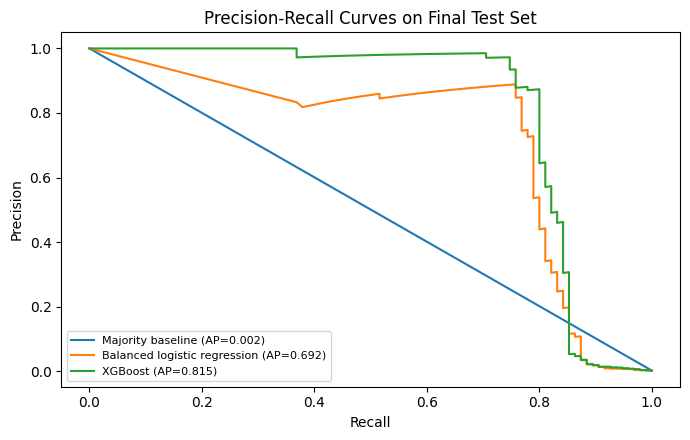

In [6]:
plt.figure(figsize=(7, 4.5))
for name in models:
    precision, recall, _ = precision_recall_curve(y_test, probabilities[name])
    ap = average_precision_score(y_test, probabilities[name])
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves on Final Test Set')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 5. Example output and weak case

The next cell shows one correctly detected fraud transaction and one fraud transaction XGBoost missed at the fixed `0.50` threshold. Only anonymized/non-sensitive fields are displayed.


In [7]:
xgb_pred = predictions['XGBoost']
xgb_prob = probabilities['XGBoost']

test_output = X_test.copy()
test_output['Actual'] = y_test.values
test_output['Predicted'] = xgb_pred
test_output['FraudProbability'] = xgb_prob

example = (
    test_output[(test_output['Actual'] == 1) & (test_output['Predicted'] == 1)]
    .sort_values('FraudProbability', ascending=False)
    .head(1)
)

weak_case = (
    test_output[(test_output['Actual'] == 1) & (test_output['Predicted'] == 0)]
    .sort_values('FraudProbability', ascending=False)
    .head(1)
)

print('Correctly detected fraud example:')
display(example[['Time','Amount','Actual','Predicted','FraudProbability']])

print('Missed fraud weak case:')
display(weak_case[['Time','Amount','Actual','Predicted','FraudProbability']])


Correctly detected fraud example:


,Time,Amount,Actual,Predicted,FraudProbability
42588,41237.0,118.3,1,1,0.999942


Missed fraud weak case:


,Time,Amount,Actual,Predicted,FraudProbability
194676,131024.0,723.21,1,0,0.457043


## 6. What this experiment supports

This experiment supports a direct comparison of three fraud-detection approaches under the same seeded 60/20/20 split and fixed decision threshold. The majority baseline demonstrates why accuracy alone is misleading for a severely imbalanced problem. Logistic regression and XGBoost can then be compared using precision, recall, F1, PR-AUC, and false positives.

The results are limited by the anonymized features and by using one historical dataset. The dataset also lacks persistent account, cardholder, and merchant identifiers, so observed financial-network relationships cannot be reconstructed from it. Graph-based modeling is therefore left as future work rather than presented as a completed experiment.

### Reproducibility settings
- Global seed: `42`
- Data split: stratified 60% train / 20% validation / 20% test
- Classification threshold: `0.50`
- XGBoost CPU threads: `1`
- Package versions are printed at the start of the notebook.

### Tools and outside resources
- Dataset: ULB Machine Learning Group credit card fraud dataset distributed through Kaggle.
- Libraries: pandas, NumPy, scikit-learn, XGBoost, and Matplotlib.
- AI assistance: ChatGPT was used to help organize, revise, and troubleshoot the experiment and documentation. All reported metrics are produced by executing this notebook on the supplied dataset.
